# Training FNO, MRBNO, and PCA Net on Nonlinear Diffusion Dataset

Train and compare three models:
1. **FNO** (Fourier Neural Operator) - layers=4, width=24, modes=12
2. **MRBNO Lift v3** (Multi-layer Reduced Basis Neural Operator with lift architecture) - layers=4, width=24
3. **PCA Net** (Simple neural network operating in PCA coefficient space) - depth=5, hidden=1024

on the nonlinear PDE: $-\nabla \cdot (e^{m(x)} \nabla u) = f$

**Note:** PCA Net and MRBNO Lift v3 use the same PCA reducer to ensure fair comparison.

**Training settings:**
- Cosine annealing LR schedule with lr=2e-3
- Gradient clipping: max_grad_norm=3.0
- Early stopping: patience=30
- Using 1k samples from the small dataset


## 1. Load Dataset and Imports


In [38]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import sys
import os

# Add models directory to path
sys.path.append('models')

from FNO_model import FNO2d
from MRBNO_lift_v3 import MRBNOLiftV3
from MRBNO_simple import PCAReducerMultiChannel
from PCANet import PCANet

print("Libraries imported successfully!")


Libraries imported successfully!


In [39]:
# Load dataset - use 10k samples
data = np.load('data/nonlinear_diffusion_dataset.npz')
# data = np.load('/pscratch/sd/d/dvod/nonlinear_diffusion_dataset_big.npz')
f_all = data['f']  # (20000, 100, 100)
m_all = data['m']  # (20000, 100, 100)
u_all = data['u']  # (20000, 100, 100)
N = int(data['N'])
L = float(data['L'])

# Use first 10k samples
num_samples = 1000
f_all = f_all[:num_samples]
m_all = m_all[:num_samples]
u_all = u_all[:num_samples]

print(f"Loaded {num_samples} samples")
print(f"Grid size: {N}x{N}")
print(f"Domain: [0, {L}]^2")

# Stack f and m as 2-channel input
X = np.stack([f_all, m_all], axis=1)  # (10000, 2, 100, 100)
Y = u_all  # (10000, 100, 100)

print(f"\nInput X shape: {X.shape}")
print(f"Output Y shape: {Y.shape}")


Loaded 1000 samples
Grid size: 100x100
Domain: [0, 1.0]^2

Input X shape: (1000, 2, 100, 100)
Output Y shape: (1000, 100, 100)


## 2. Normalize and Split Data


In [40]:
# Train/val/test split (70/20/10 like hyperparameter_sweep.py)
# Use actual length of loaded data, not num_samples
actual_samples = len(X)
train_frac = 0.7
val_frac = 0.2
n_train = int(train_frac * actual_samples)
n_val = int(val_frac * actual_samples)

X_train, Y_train = X[:n_train], Y[:n_train]
X_val, Y_val = X[n_train:n_train+n_val], Y[n_train:n_train+n_val]
X_test, Y_test = X[n_train+n_val:], Y[n_train+n_val:]

print(f"\nTraining samples: {len(X_train)}")
print(f"Validation samples: {len(X_val)}")
print(f"Test samples: {len(X_test)}")

# Normalize using train statistics only
x_mean = X_train.mean()
x_std = X_train.std()
y_mean = Y_train.mean()
y_std = Y_train.std()

X_train = (X_train - x_mean) / (x_std + 1e-8)
Y_train = (Y_train - y_mean) / (y_std + 1e-8)
X_val = (X_val - x_mean) / (x_std + 1e-8)
Y_val = (Y_val - y_mean) / (y_std + 1e-8)
X_test = (X_test - x_mean) / (x_std + 1e-8)
Y_test = (Y_test - y_mean) / (y_std + 1e-8)

print(f"X normalization: mean={x_mean:.4f}, std={x_std:.4f}")
print(f"Y normalization: mean={y_mean:.4f}, std={y_std:.4f}")


Training samples: 700
Validation samples: 200
Test samples: 100
X normalization: mean=0.0340, std=1.7365
Y normalization: mean=0.0047, std=0.0922


## 3. Prepare Data and PCA


In [41]:
# Convert to PyTorch tensors
X_train_t = torch.from_numpy(X_train).float()  # (7000, 2, 100, 100)
Y_train_t = torch.from_numpy(Y_train).float().unsqueeze(1)  # (7000, 1, 100, 100)
X_val_t = torch.from_numpy(X_val).float()  # (2000, 2, 100, 100)
Y_val_t = torch.from_numpy(Y_val).float().unsqueeze(1)  # (2000, 1, 100, 100)

print(f"Training data: X={X_train_t.shape}, Y={Y_train_t.shape}")
print(f"Validation data: X={X_val_t.shape}, Y={Y_val_t.shape}")

# Create data loaders
batch_size = 32
train_loader = DataLoader(TensorDataset(X_train_t, Y_train_t), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, Y_val_t), batch_size=batch_size, shuffle=False)

# Compute PCA ONCE - shared by both MRBNO Lift v3 and PCA Net
# Using settings matching hyperparameter_sweep.py: whiten=False (default), bc_weight=1.0, boundary_threshold=0.1
rb = PCAReducerMultiChannel(
    bc_weight=1.0, 
    boundary_threshold=0.1, 
    use_boundary_weighting=False,
    # whiten not specified (defaults to False)
).fit(X_train, Y_train)
epsilon = 1e-5
k_in, k_out = rb.k_from_cutoff(j_in=1-1*epsilon, j_out=1-epsilon)

print(f"\nPCA components (shared by MRBNO and PCA Net): k_in={k_in}, k_out={k_out}")
print(f"Boundary condition awareness: bc_weight={rb.bc_weight}, threshold={rb.boundary_threshold}")
print(f"PCA whiten: {getattr(rb, 'whiten', False)}")


Training data: X=torch.Size([700, 2, 100, 100]), Y=torch.Size([700, 1, 100, 100])
Validation data: X=torch.Size([200, 2, 100, 100]), Y=torch.Size([200, 1, 100, 100])

PCA components (shared by MRBNO and PCA Net): k_in=121, k_out=59
Boundary condition awareness: bc_weight=1.0, threshold=0.1
PCA whiten: False



PCA ANALYSIS AND SAMPLE VISUALIZATION


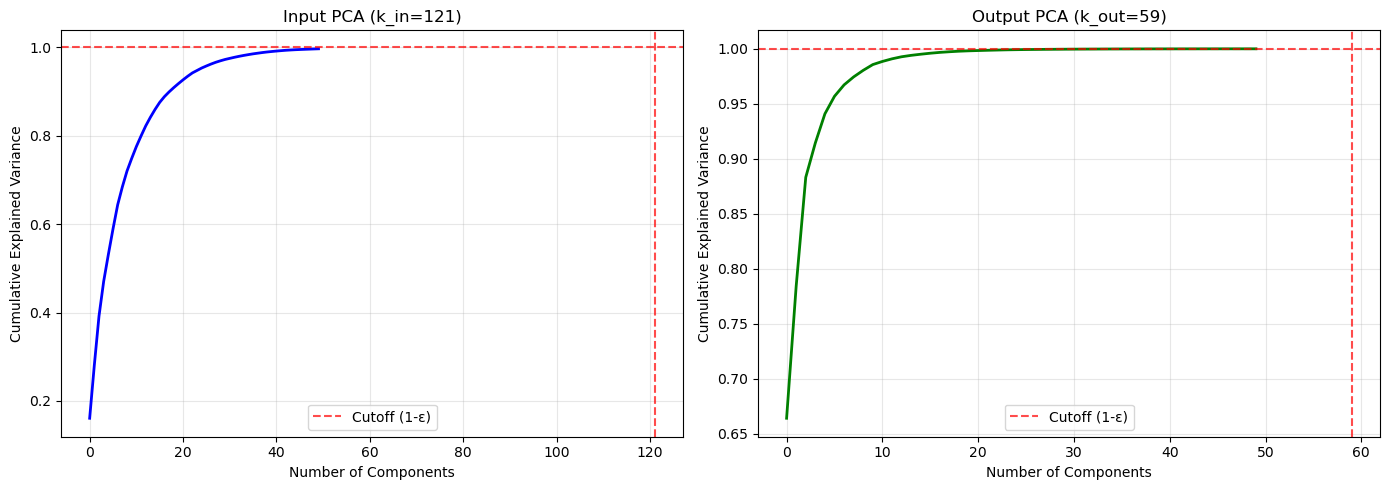

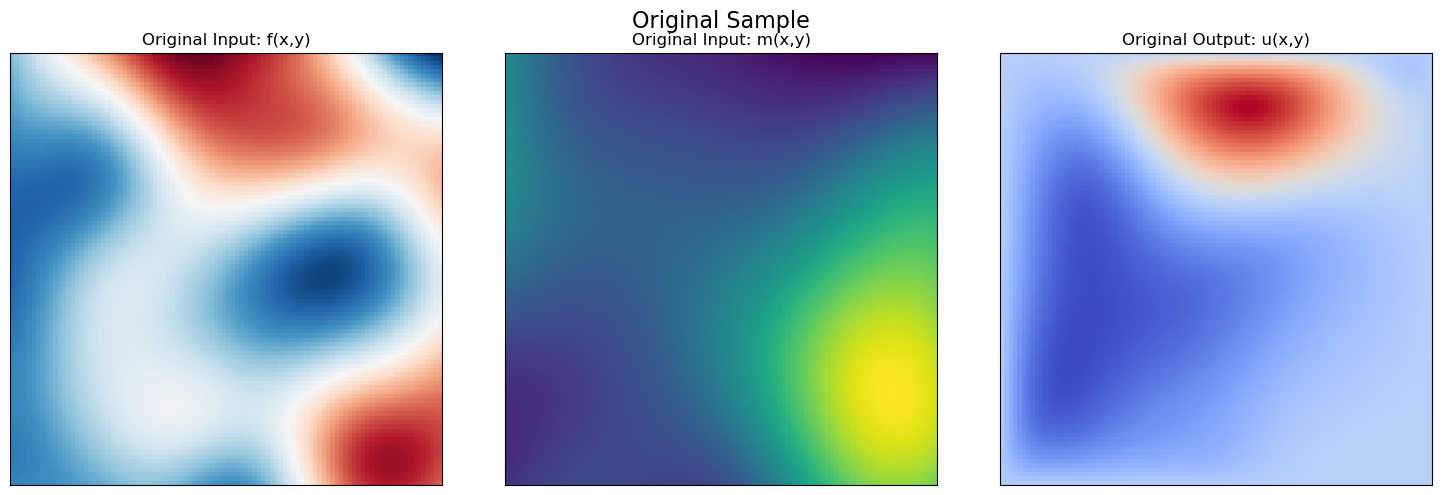

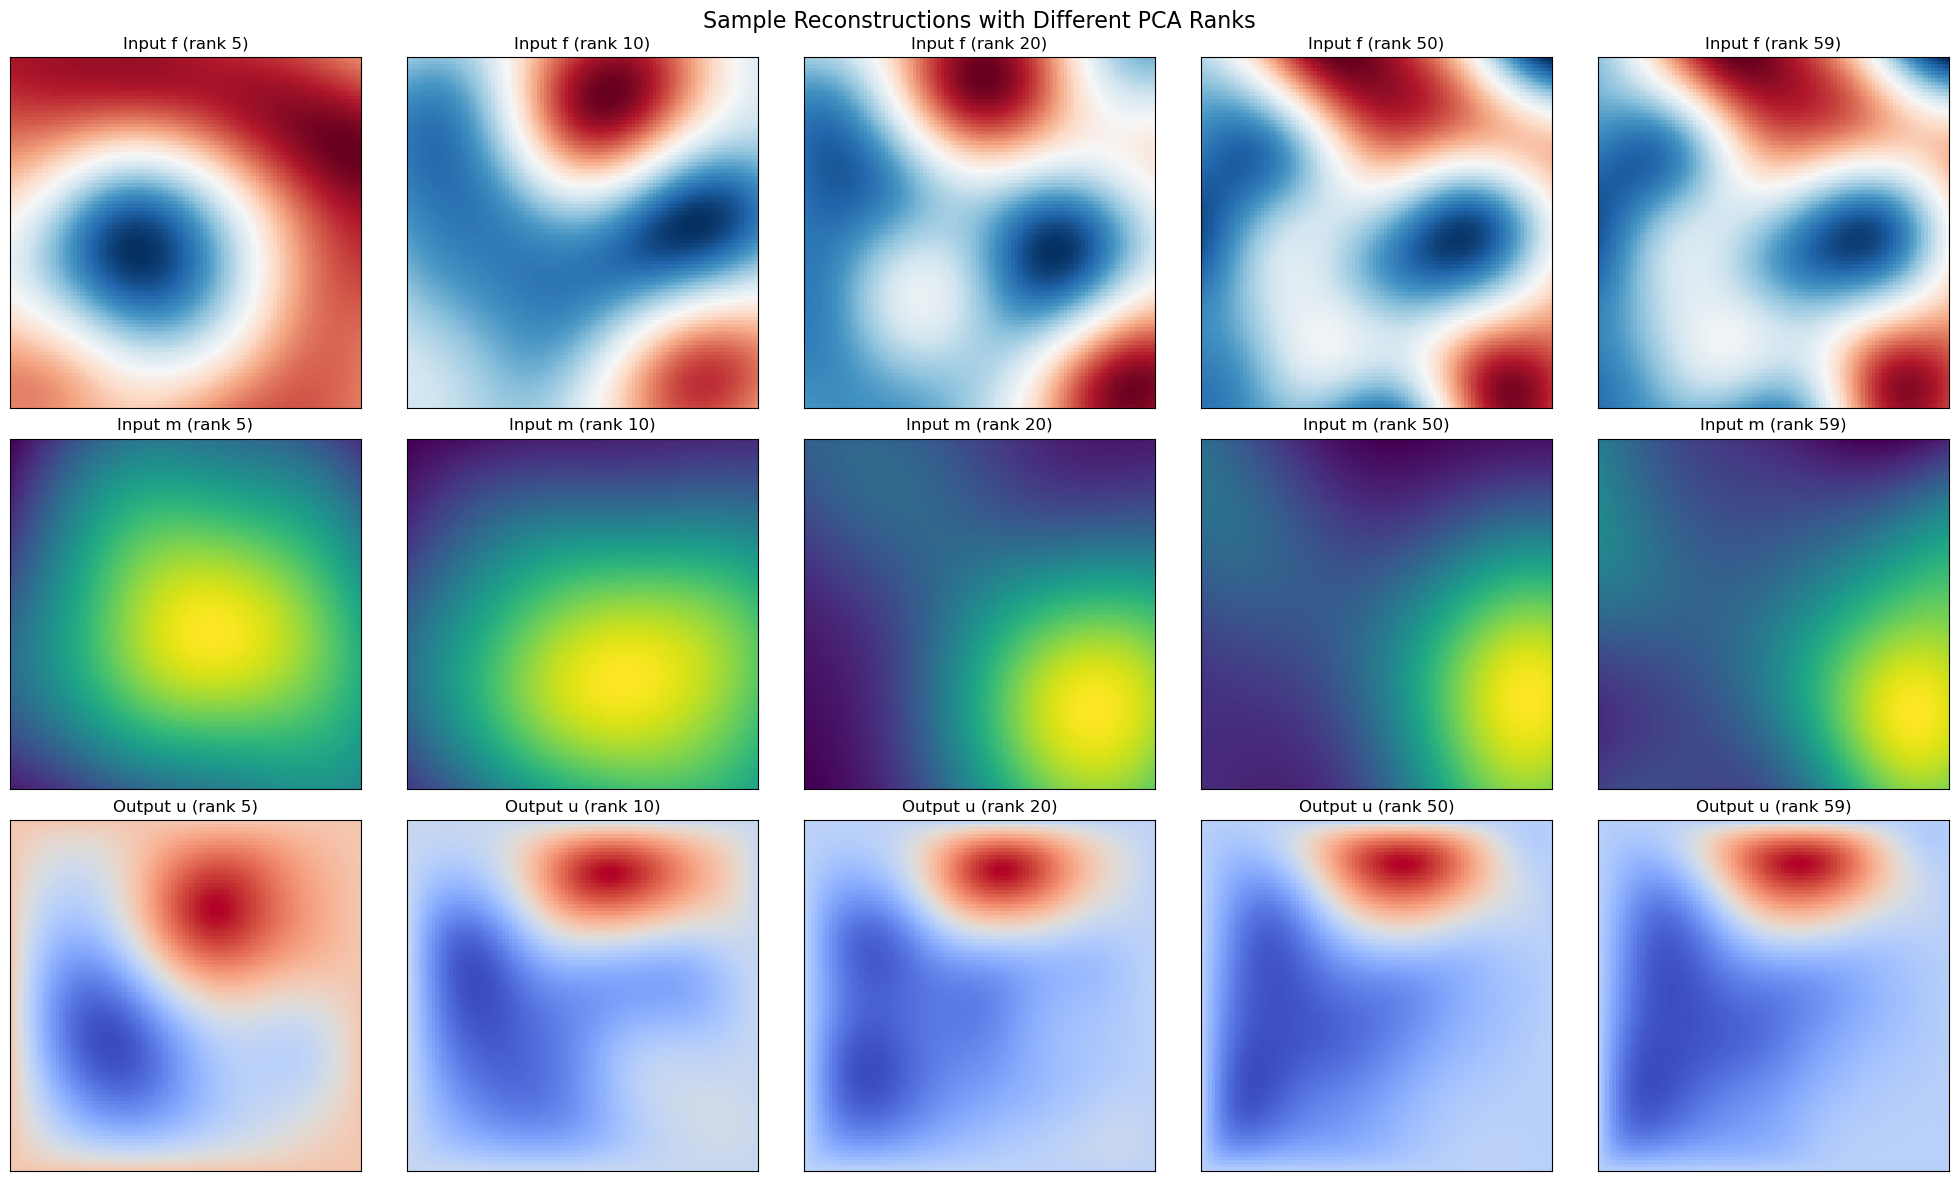


Reconstruction errors for sample 0:
Rank	Input MSE	Output MSE
-----------------------------------
5	6.44e-01	4.20e-03
10	2.68e-01	6.80e-04
20	6.67e-02	1.45e-04
50	4.27e-03	2.62e-06
59	1.32e-03	1.28e-06


In [42]:
# Visualize PCA components and sample reconstructions
print("\n" + "="*70)
print("PCA ANALYSIS AND SAMPLE VISUALIZATION")
print("="*70)

# Plot PCA explained variance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Input PCA variance
axes[0].plot(np.cumsum(rb.pca_in.explained_variance_ratio_[:50]), 'b-', linewidth=2)
axes[0].axhline(y=1-epsilon, color='r', linestyle='--', alpha=0.7, label=f'Cutoff (1-ε)')
axes[0].axvline(x=k_in, color='r', linestyle='--', alpha=0.7)
axes[0].set_xlabel('Number of Components')
axes[0].set_ylabel('Cumulative Explained Variance')
axes[0].set_title(f'Input PCA (k_in={k_in})')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Output PCA variance
axes[1].plot(np.cumsum(rb.pca_out.explained_variance_ratio_[:50]), 'g-', linewidth=2)
axes[1].axhline(y=1-epsilon, color='r', linestyle='--', alpha=0.7, label=f'Cutoff (1-ε)')
axes[1].axvline(x=k_out, color='r', linestyle='--', alpha=0.7)
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Explained Variance')
axes[1].set_title(f'Output PCA (k_out={k_out})')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Visualize sample reconstructions with different ranks
sample_idx = 0
x_sample = X_train[sample_idx:sample_idx+1]  # (1, 2, 100, 100)
y_sample = Y_train[sample_idx:sample_idx+1]  # (1, 100, 100)

# Show original sample first
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(x_sample[0, 0], origin='lower', cmap='RdBu_r')
axes[0].set_title('Original Input: f(x,y)')
axes[0].set_xticks([])
axes[0].set_yticks([])

axes[1].imshow(x_sample[0, 1], origin='lower', cmap='viridis')
axes[1].set_title('Original Input: m(x,y)')
axes[1].set_xticks([])
axes[1].set_yticks([])

axes[2].imshow(y_sample[0], origin='lower', cmap='coolwarm')
axes[2].set_title('Original Output: u(x,y)')
axes[2].set_xticks([])
axes[2].set_yticks([])

plt.suptitle('Original Sample', fontsize=16)
plt.tight_layout()
plt.show()

# Reconstruct with different numbers of components
ranks_to_test = [5, 10, 20, 50, k_out]

fig, axes = plt.subplots(3, len(ranks_to_test), figsize=(20, 12))

for i, rank in enumerate(ranks_to_test):
    # Input reconstruction - need to use full multi-channel input
    x_flat = x_sample.reshape(1, -1)  # Flatten all channels: (1, 20000)
    x_coeffs = rb.pca_in.transform(x_flat)[:, :rank]
    x_reconstructed = rb.pca_in.inverse_transform(
        np.pad(x_coeffs, ((0, 0), (0, rb.pca_in.n_components_ - rank)), 'constant')
    ).reshape(1, 2, 100, 100)
    
    # Show both input channels
    axes[0, i].imshow(x_reconstructed[0, 0], origin='lower', cmap='RdBu_r')
    axes[0, i].set_title(f'Input f (rank {rank})')
    axes[0, i].set_xticks([])
    axes[0, i].set_yticks([])
    
    axes[1, i].imshow(x_reconstructed[0, 1], origin='lower', cmap='viridis')
    axes[1, i].set_title(f'Input m (rank {rank})')
    axes[1, i].set_xticks([])
    axes[1, i].set_yticks([])
    
    # Output reconstruction
    y_flat = y_sample.reshape(1, -1)  # (1, 10000)
    y_coeffs = rb.pca_out.transform(y_flat)[:, :rank]
    y_reconstructed = rb.pca_out.inverse_transform(
        np.pad(y_coeffs, ((0, 0), (0, rb.pca_out.n_components_ - rank)), 'constant')
    ).reshape(100, 100)
    
    axes[2, i].imshow(y_reconstructed, origin='lower', cmap='coolwarm')
    axes[2, i].set_title(f'Output u (rank {rank})')
    axes[2, i].set_xticks([])
    axes[2, i].set_yticks([])

plt.suptitle('Sample Reconstructions with Different PCA Ranks', fontsize=16)
plt.tight_layout()
plt.show()

# Show reconstruction errors
print(f"\nReconstruction errors for sample {sample_idx}:")
print("Rank\tInput MSE\tOutput MSE")
print("-" * 35)
for rank in ranks_to_test:
    # Input error - use full multi-channel input
    x_flat = x_sample.reshape(1, -1)
    x_coeffs = rb.pca_in.transform(x_flat)[:, :rank]
    x_reconstructed = rb.pca_in.inverse_transform(
        np.pad(x_coeffs, ((0, 0), (0, rb.pca_in.n_components_ - rank)), 'constant')
    ).reshape(1, 2, 100, 100)
    x_mse = np.mean((x_reconstructed - x_sample)**2)
    
    # Output error
    y_flat = y_sample.reshape(1, -1)
    y_coeffs = rb.pca_out.transform(y_flat)[:, :rank]
    y_reconstructed = rb.pca_out.inverse_transform(
        np.pad(y_coeffs, ((0, 0), (0, rb.pca_out.n_components_ - rank)), 'constant')
    ).reshape(100, 100)
    y_mse = np.mean((y_reconstructed - y_sample[0])**2)
    
    print(f"{rank}\t{x_mse:.2e}\t{y_mse:.2e}")


## 4. Training Function


In [43]:
def train_model(model, train_loader, val_loader, epochs=300, lr=2e-3, weight_decay=1e-4, max_grad_norm=3.0, 
                device='cpu', early_stopping_patience=50, early_stopping_min_delta=0.0):
    """Train model with cosine annealing LR schedule and early stopping."""
    import time
    start_time = time.time()
    
    model.to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay,
        betas=(0.9, 0.999),
        eps=1e-8
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=0.0)
    criterion = nn.MSELoss()
    
    train_losses = []
    val_losses = []
    best_val_loss = float('inf')
    best_epoch = 0
    patience_counter = 0
    
    # Check if validation set is empty
    has_val = len(val_loader.dataset) > 0
    
    for epoch in range(epochs):
        # Training phase
        model.train()
        train_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
            optimizer.step()
            train_loss += loss.item() * xb.size(0)
        train_loss /= len(train_loader.dataset)
        
        # Validation phase
        if has_val:
            model.eval()
            val_loss = 0.0
            with torch.no_grad():
                for xb, yb in val_loader:
                    xb, yb = xb.to(device), yb.to(device)
                    pred = model(xb)
                    loss = criterion(pred, yb)
                    val_loss += loss.item() * xb.size(0)
            val_loss /= len(val_loader.dataset)
        else:
            val_loss = float('inf')  # No validation data
        
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        
        # Early stopping logic
        improved = False
        if has_val:
            if val_loss < best_val_loss - early_stopping_min_delta:
                best_val_loss = val_loss
                best_epoch = epoch
                patience_counter = 0
                improved = True
            else:
                patience_counter += 1
        else:
            # If no validation, use training loss
            if train_loss < best_val_loss - early_stopping_min_delta:
                best_val_loss = train_loss
                best_epoch = epoch
                patience_counter = 0
                improved = True
            else:
                patience_counter += 1
        
        scheduler.step()
        
        if (epoch + 1) % 10 == 0 or epoch == 0:
            if has_val:
                print(f"[{epoch+1:03d}/{epochs}] train={train_loss:.4e} val={val_loss:.4e} lr={scheduler.get_last_lr()[0]:.2e} (best: {best_val_loss:.4e} @ epoch {best_epoch+1})")
            else:
                print(f"[{epoch+1:03d}/{epochs}] train={train_loss:.4e} (no val) lr={scheduler.get_last_lr()[0]:.2e} (best: {best_val_loss:.4e} @ epoch {best_epoch+1})")
        
        # Early stopping
        if patience_counter >= early_stopping_patience:
            print(f"Early stopping triggered at epoch {epoch+1} (patience={early_stopping_patience})")
            break
    
    training_time = time.time() - start_time
    
    return train_losses, val_losses, best_val_loss, training_time, best_epoch + 1


## 5. Train All Three Models


In [44]:
device = torch.device("cuda" if torch.cuda.is_available() else 
                      "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cuda


## 5a. Train FNO Model


In [45]:
# Train FNO model
print("\n" + "="*70)
print("TRAINING FNO")
print("="*70)
fno_model = FNO2d(in_channels=2, out_channels=1, width=24, modes=(12, 12), n_layers=4)
print(f"FNO Parameters: {sum(p.numel() for p in fno_model.parameters()):,}")
fno_train_losses, fno_val_losses, fno_best_val, fno_training_time, fno_best_epoch = train_model(
    fno_model, train_loader, val_loader, epochs=300, lr=2e-3, max_grad_norm=3.0, 
    device=device, early_stopping_patience=30
)
os.makedirs('checkpoints', exist_ok=True)
torch.save(fno_model.state_dict(), 'checkpoints/fno_nonlinear_best.pt')
print(f"FNO model saved to checkpoints/fno_nonlinear_best.pt")
print(f"Training time: {fno_training_time:.2f} seconds ({fno_training_time/60:.2f} minutes)")



TRAINING FNO
FNO Parameters: 335,065
[001/300] train=5.4215e-01 val=1.8960e-01 lr=2.00e-03 (best: 1.8960e-01 @ epoch 1)
[010/300] train=6.4070e-02 val=5.1137e-02 lr=1.99e-03 (best: 5.1137e-02 @ epoch 10)
[020/300] train=1.8839e-02 val=3.5457e-02 lr=1.98e-03 (best: 3.4748e-02 @ epoch 19)
[030/300] train=1.4279e-02 val=3.3083e-02 lr=1.95e-03 (best: 3.3083e-02 @ epoch 30)
[040/300] train=7.7974e-03 val=2.7305e-02 lr=1.91e-03 (best: 2.7305e-02 @ epoch 40)
[050/300] train=1.0253e-02 val=2.8153e-02 lr=1.87e-03 (best: 2.7305e-02 @ epoch 40)
[060/300] train=8.1242e-03 val=2.7274e-02 lr=1.81e-03 (best: 2.6819e-02 @ epoch 55)
[070/300] train=6.3299e-03 val=2.9138e-02 lr=1.74e-03 (best: 2.6101e-02 @ epoch 69)
[080/300] train=3.5177e-03 val=2.5316e-02 lr=1.67e-03 (best: 2.4996e-02 @ epoch 79)
[090/300] train=2.9653e-03 val=2.5170e-02 lr=1.59e-03 (best: 2.4255e-02 @ epoch 89)
[100/300] train=3.7645e-03 val=2.5050e-02 lr=1.50e-03 (best: 2.4255e-02 @ epoch 89)
[110/300] train=2.3780e-03 val=2.4179e-

## 5b. Train MRBNO Lift v3 Model


In [46]:
# Train MRBNO Lift v3 model (using shared PCA reducer)
print("\n" + "="*70)
print("TRAINING MRBNO LIFT V3")
print("="*70)

mrbno_lift_v3_model = MRBNOLiftV3(
    width=24,
    rb=rb,
    k_in=k_in,
    k_out=k_out,
    layers=4,
    dropout=0.0,
    init_scale=0.1,
    use_skip_connections=True,
    use_batch_norm=True,
    use_coordinates=True,
)

mrbno_lift_v3_params = sum(p.numel() for p in mrbno_lift_v3_model.parameters())
print(f"MRBNO Lift v3 Parameters: {mrbno_lift_v3_params:,}")

mrbno_lift_v3_train_losses, mrbno_lift_v3_val_losses, mrbno_lift_v3_best_val, mrbno_lift_v3_training_time, mrbno_lift_v3_best_epoch = train_model(
    mrbno_lift_v3_model, train_loader, val_loader, epochs=300, lr=2e-3, max_grad_norm=3.0, weight_decay=1e-4, 
    device=device, early_stopping_patience=30
)

os.makedirs('checkpoints', exist_ok=True)
torch.save(mrbno_lift_v3_model.state_dict(), 'checkpoints/mrbno_lift_v3_nonlinear_best.pt')
print(f"MRBNO Lift v3 model saved to checkpoints/mrbno_lift_v3_nonlinear_best.pt")
print(f"Training time: {mrbno_lift_v3_training_time:.2f} seconds ({mrbno_lift_v3_training_time/60:.2f} minutes)")


TRAINING MRBNO LIFT V3
MRBNO Lift v3 Parameters: 18,564,850
[001/300] train=9.4468e-01 val=6.0365e-01 lr=2.00e-03 (best: 6.0365e-01 @ epoch 1)
[010/300] train=2.8190e-01 val=2.0099e-01 lr=1.99e-03 (best: 2.0099e-01 @ epoch 10)
[020/300] train=1.1573e-01 val=1.0020e-01 lr=1.98e-03 (best: 1.0020e-01 @ epoch 20)
[030/300] train=6.6982e-02 val=7.9271e-02 lr=1.95e-03 (best: 7.7633e-02 @ epoch 28)
[040/300] train=4.1770e-02 val=6.2840e-02 lr=1.91e-03 (best: 6.2840e-02 @ epoch 40)
[050/300] train=4.0301e-02 val=5.7703e-02 lr=1.87e-03 (best: 5.7703e-02 @ epoch 50)
[060/300] train=3.4279e-02 val=5.0013e-02 lr=1.81e-03 (best: 5.0013e-02 @ epoch 60)
[070/300] train=2.3951e-02 val=5.1349e-02 lr=1.74e-03 (best: 4.5504e-02 @ epoch 69)
[080/300] train=2.7246e-02 val=4.7857e-02 lr=1.67e-03 (best: 4.4965e-02 @ epoch 78)
[090/300] train=2.1101e-02 val=4.2755e-02 lr=1.59e-03 (best: 4.2755e-02 @ epoch 90)
[100/300] train=1.7959e-02 val=4.2171e-02 lr=1.50e-03 (best: 3.9985e-02 @ epoch 91)
[110/300] train=

In [47]:
## 5c. Train PCA Net Model


In [48]:
# Train PCA Net model (using shared PCA reducer)
print("\n" + "="*70)
print("TRAINING PCA NET")
print("="*70)

pcanet_model = PCANet(
    rb=rb,
    k_in=k_in,
    k_out=k_out,
    hidden=1024,
    depth=5,
    dropout=0.0,
    init_scale=0.1,
)

pcanet_params = sum(p.numel() for p in pcanet_model.parameters())
print(f"PCA Net Parameters: {pcanet_params:,}")

pcanet_train_losses, pcanet_val_losses, pcanet_best_val, pcanet_training_time, pcanet_best_epoch = train_model(
    pcanet_model, train_loader, val_loader, epochs=300, lr=2e-3, max_grad_norm=3.0, weight_decay=1e-4, 
    device=device, early_stopping_patience=30
)

os.makedirs('checkpoints', exist_ok=True)
torch.save(pcanet_model.state_dict(), 'checkpoints/pcanet_nonlinear_best.pt')
print(f"PCA Net model saved to checkpoints/pcanet_nonlinear_best.pt")
print(f"Training time: {pcanet_training_time:.2f} seconds ({pcanet_training_time/60:.2f} minutes)")

print("\n" + "="*70)
print("TRAINING COMPLETE!")
print("="*70)
print(f"\nFinal Results Summary:")
print(f"  FNO:           best val loss = {fno_best_val:.4e} (epoch {fno_best_epoch})")
print(f"  MRBNO Lift v3: best val loss = {mrbno_lift_v3_best_val:.4e} (epoch {mrbno_lift_v3_best_epoch})")
print(f"  PCA Net:       best val loss = {pcanet_best_val:.4e} (epoch {pcanet_best_epoch})")


TRAINING PCA NET
PCA Net Parameters: 4,383,803
[001/300] train=8.9324e-01 val=3.7931e-01 lr=2.00e-03 (best: 3.7931e-01 @ epoch 1)
[010/300] train=4.8618e-01 val=3.2052e-01 lr=1.99e-03 (best: 3.1255e-01 @ epoch 6)
[020/300] train=4.0148e-01 val=3.0832e-01 lr=1.98e-03 (best: 2.8761e-01 @ epoch 19)
[030/300] train=3.9002e-01 val=3.0396e-01 lr=1.95e-03 (best: 2.7304e-01 @ epoch 27)
[040/300] train=3.8018e-01 val=2.8328e-01 lr=1.91e-03 (best: 2.5757e-01 @ epoch 39)
[050/300] train=2.9394e-01 val=2.5293e-01 lr=1.87e-03 (best: 2.4658e-01 @ epoch 47)
[060/300] train=1.6844e-01 val=2.0261e-01 lr=1.81e-03 (best: 2.0261e-01 @ epoch 60)
[070/300] train=1.5487e-01 val=1.9833e-01 lr=1.74e-03 (best: 1.8395e-01 @ epoch 68)
[080/300] train=9.3903e-02 val=2.0056e-01 lr=1.67e-03 (best: 1.8395e-01 @ epoch 68)
[090/300] train=7.8394e-02 val=2.0485e-01 lr=1.59e-03 (best: 1.7387e-01 @ epoch 87)
[100/300] train=7.7663e-02 val=2.0573e-01 lr=1.50e-03 (best: 1.6982e-01 @ epoch 99)
[110/300] train=6.8551e-02 val

## 6. Training Results and Comparison


In [49]:
# Compare results from all models and compute relative L1 errors
print("\n" + "="*70)
print("TRAINING COMPLETE - SUMMARY")
print("="*70)

# Get parameter counts (fno_params might not be defined, so compute it here)
fno_params = sum(p.numel() for p in fno_model.parameters())

# Compute relative L1 errors on validation set
def compute_rel_l1_error(model, val_loader, device, y_mean, y_std):
    """Compute relative L1 error: ||u_pred - u_true||_1 / ||u_true||_1"""
    model.eval()
    total_l1_error = 0.0
    total_l1_norm_true = 0.0
    
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = model(xb)
            
            # Denormalize
            pred_denorm = pred * y_std + y_mean
            yb_denorm = yb * y_std + y_mean
            
            # Compute L1 norms
            l1_error = torch.abs(pred_denorm - yb_denorm).sum().item()
            l1_norm_true = torch.abs(yb_denorm).sum().item()
            
            total_l1_error += l1_error
            total_l1_norm_true += l1_norm_true
    
    return total_l1_error / total_l1_norm_true if total_l1_norm_true > 0 else float('inf')

fno_rel_l1 = compute_rel_l1_error(fno_model, val_loader, device, y_mean, y_std)
mrbno_lift_v3_rel_l1 = compute_rel_l1_error(mrbno_lift_v3_model, val_loader, device, y_mean, y_std)
pcanet_rel_l1 = compute_rel_l1_error(pcanet_model, val_loader, device, y_mean, y_std)

# Measure inference time
import time
def measure_inference_time(model, val_loader, device, n_runs=10):
    """Measure average inference time per batch"""
    model.eval()
    times = []
    
    with torch.no_grad():
        for _ in range(n_runs):
            for xb, yb in val_loader:
                xb = xb.to(device)
                torch.cuda.synchronize() if device.type == 'cuda' else None
                start = time.time()
                _ = model(xb)
                torch.cuda.synchronize() if device.type == 'cuda' else None
                times.append(time.time() - start)
                break  # Only measure first batch
    return np.mean(times)

fno_inference_time = measure_inference_time(fno_model, val_loader, device)
mrbno_lift_v3_inference_time = measure_inference_time(mrbno_lift_v3_model, val_loader, device)
pcanet_inference_time = measure_inference_time(pcanet_model, val_loader, device)

models_summary = [
    ("FNO", fno_train_losses, fno_val_losses, fno_best_val, fno_params, 
     fno_training_time, fno_inference_time, fno_rel_l1, fno_best_epoch),
    ("MRBNO Lift v3", mrbno_lift_v3_train_losses, mrbno_lift_v3_val_losses, mrbno_lift_v3_best_val, 
     mrbno_lift_v3_params, mrbno_lift_v3_training_time, mrbno_lift_v3_inference_time, 
     mrbno_lift_v3_rel_l1, mrbno_lift_v3_best_epoch),
    ("PCA Net", pcanet_train_losses, pcanet_val_losses, pcanet_best_val, pcanet_params,
     pcanet_training_time, pcanet_inference_time, pcanet_rel_l1, pcanet_best_epoch),
]

print(f"\n{'Model':<20} {'Params':<12} {'Best Val Loss':<15} {'Rel L1 Error':<15} {'Train Time (min)':<18} {'Inf Time (ms)':<15} {'Best Epoch':<12}")
print("-" * 120)
for model_name, train_losses, val_losses, best_val, params, train_time, inf_time, rel_l1, best_epoch in models_summary:
    print(f"{model_name:<20} {params:>10,}  {best_val:>12.4e}  {rel_l1*100:>13.2f}%  {train_time/60:>16.2f}  {inf_time*1000:>13.2f}  {best_epoch:>10}")



TRAINING COMPLETE - SUMMARY

Model                Params       Best Val Loss   Rel L1 Error    Train Time (min)   Inf Time (ms)   Best Epoch  
------------------------------------------------------------------------------------------------------------------------
FNO                     335,065    2.2656e-02          20.36%              1.58           4.62         230
MRBNO Lift v3        18,564,850    2.5672e-02          20.17%              1.61           4.81         264
PCA Net               4,383,803    1.6528e-01          54.49%              0.18           0.75         101


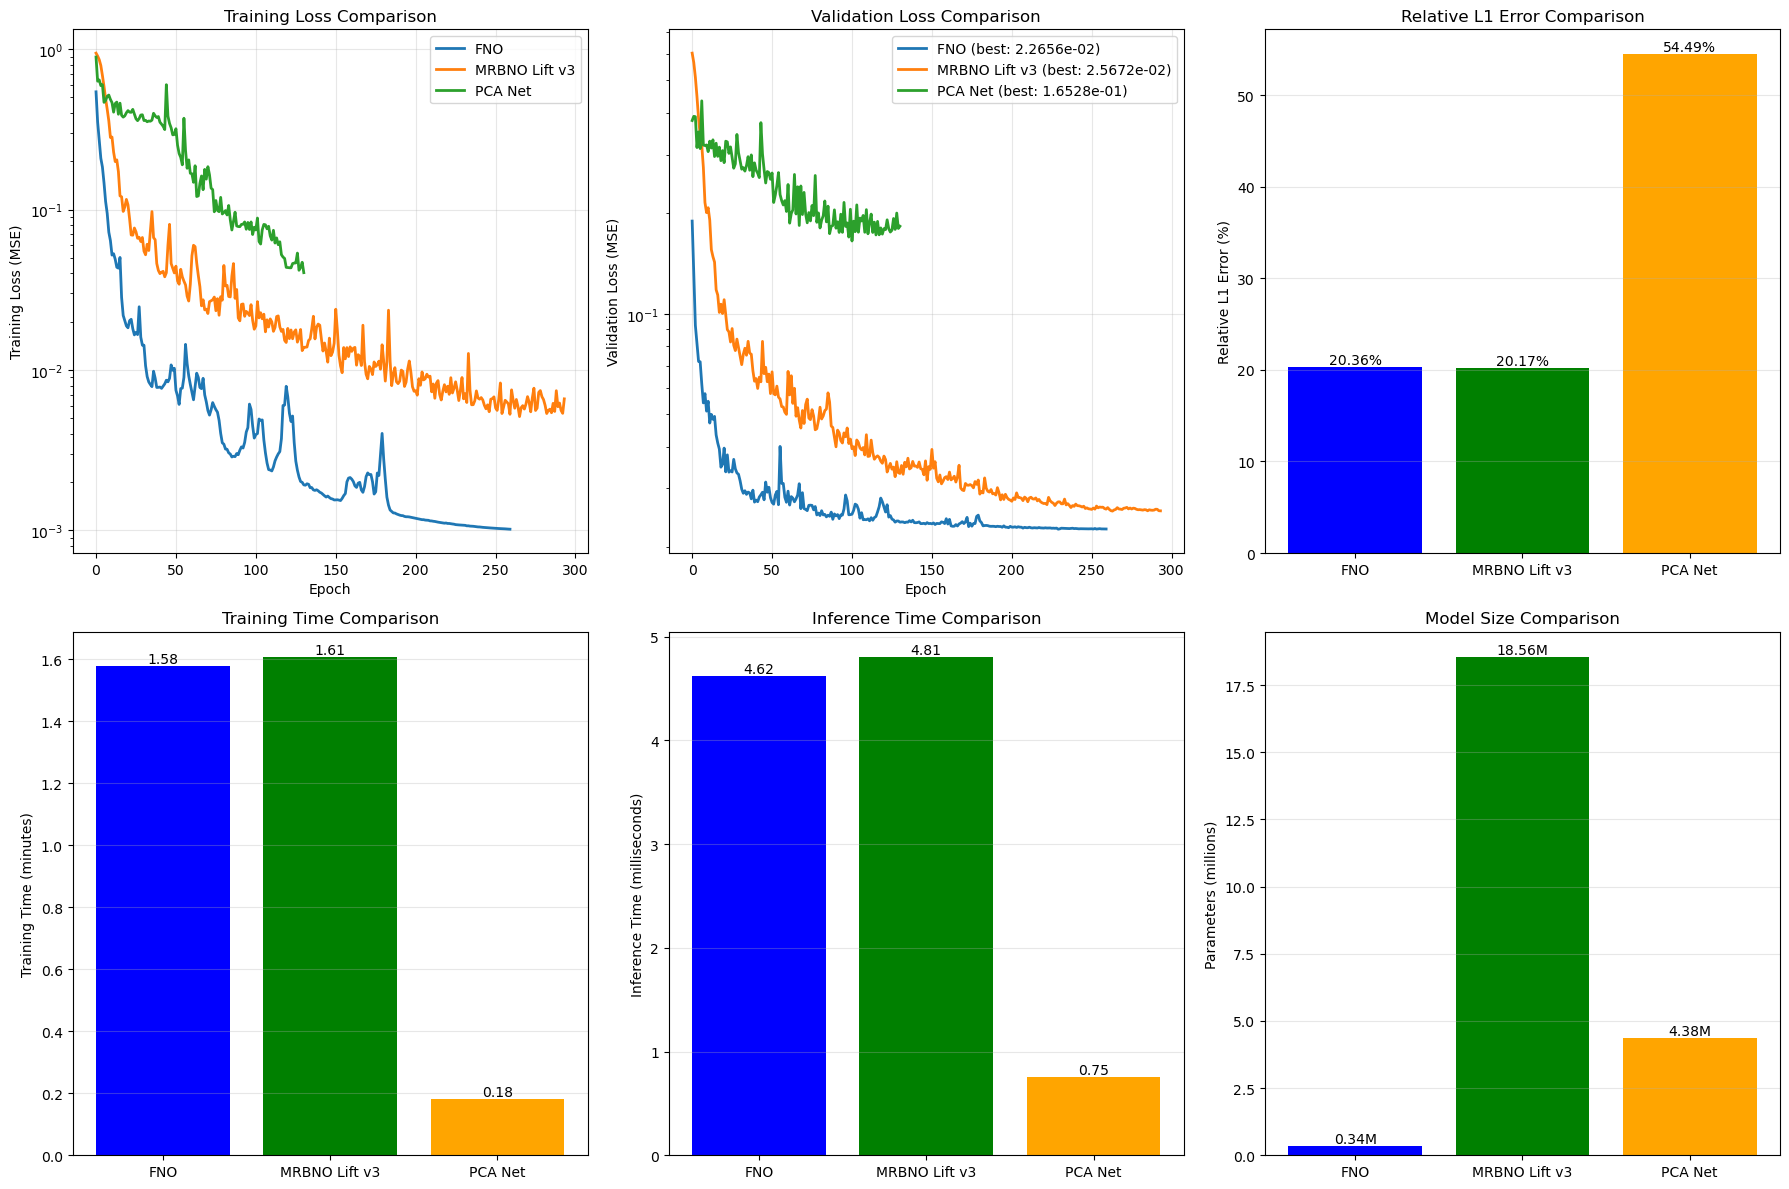

In [50]:
# Comprehensive Training Curves Comparison with Relative L1 Errors
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Training Loss
axes[0, 0].plot(fno_train_losses, label='FNO', linewidth=2)
axes[0, 0].plot(mrbno_lift_v3_train_losses, label='MRBNO Lift v3', linewidth=2)
axes[0, 0].plot(pcanet_train_losses, label='PCA Net', linewidth=2)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Training Loss (MSE)')
axes[0, 0].set_title('Training Loss Comparison')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].set_yscale('log')

# Validation Loss
axes[0, 1].plot(fno_val_losses, label=f'FNO (best: {fno_best_val:.4e})', linewidth=2)
axes[0, 1].plot(mrbno_lift_v3_val_losses, label=f'MRBNO Lift v3 (best: {mrbno_lift_v3_best_val:.4e})', linewidth=2)
axes[0, 1].plot(pcanet_val_losses, label=f'PCA Net (best: {pcanet_best_val:.4e})', linewidth=2)
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Validation Loss (MSE)')
axes[0, 1].set_title('Validation Loss Comparison')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].set_yscale('log')

# Relative L1 Error Comparison
models = ['FNO', 'MRBNO Lift v3', 'PCA Net']
rel_l1_errors = [fno_rel_l1*100, mrbno_lift_v3_rel_l1*100, pcanet_rel_l1*100]
axes[0, 2].bar(models, rel_l1_errors, color=['blue', 'green', 'orange'])
axes[0, 2].set_ylabel('Relative L1 Error (%)')
axes[0, 2].set_title('Relative L1 Error Comparison')
axes[0, 2].grid(True, alpha=0.3, axis='y')
for i, (model, error_val) in enumerate(zip(models, rel_l1_errors)):
    axes[0, 2].text(i, error_val, f'{error_val:.2f}%', ha='center', va='bottom')

# Training Time Comparison
train_times = [fno_training_time/60, mrbno_lift_v3_training_time/60, pcanet_training_time/60]
axes[1, 0].bar(models, train_times, color=['blue', 'green', 'orange'])
axes[1, 0].set_ylabel('Training Time (minutes)')
axes[1, 0].set_title('Training Time Comparison')
axes[1, 0].grid(True, alpha=0.3, axis='y')
for i, (model, time_val) in enumerate(zip(models, train_times)):
    axes[1, 0].text(i, time_val, f'{time_val:.2f}', ha='center', va='bottom')

# Inference Time Comparison
inf_times = [fno_inference_time*1000, mrbno_lift_v3_inference_time*1000, pcanet_inference_time*1000]
axes[1, 1].bar(models, inf_times, color=['blue', 'green', 'orange'])
axes[1, 1].set_ylabel('Inference Time (milliseconds)')
axes[1, 1].set_title('Inference Time Comparison')
axes[1, 1].grid(True, alpha=0.3, axis='y')
for i, (model, time_val) in enumerate(zip(models, inf_times)):
    axes[1, 1].text(i, time_val, f'{time_val:.2f}', ha='center', va='bottom')

# Parameters Comparison
params = [fno_params/1e6, mrbno_lift_v3_params/1e6, pcanet_params/1e6]
axes[1, 2].bar(models, params, color=['blue', 'green', 'orange'])
axes[1, 2].set_ylabel('Parameters (millions)')
axes[1, 2].set_title('Model Size Comparison')
axes[1, 2].grid(True, alpha=0.3, axis='y')
for i, (model, param_val) in enumerate(zip(models, params)):
    axes[1, 2].text(i, param_val, f'{param_val:.2f}M', ha='center', va='bottom')

plt.tight_layout()
plt.show()


## 7. Visualize Predictions


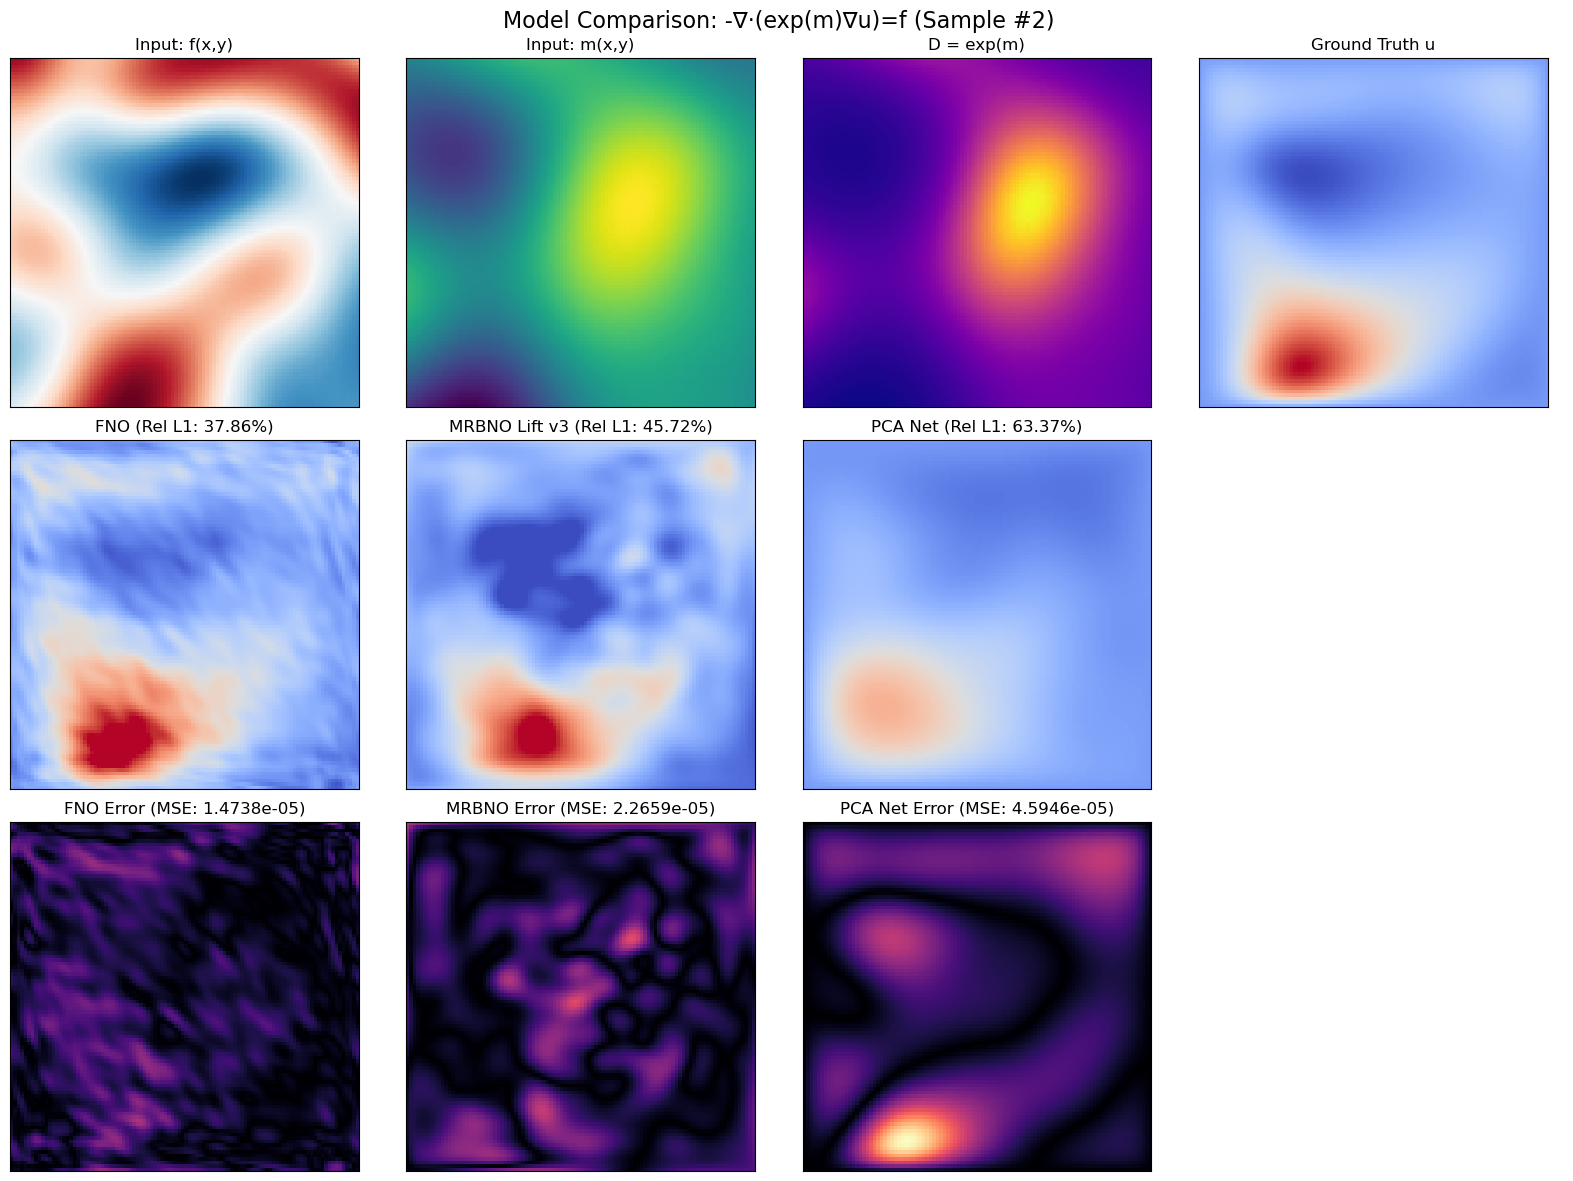

In [51]:
# Pick validation sample and get predictions with relative L1 errors
idx = 2
x_sample = X_val_t[idx:idx+1].to(device)
y_true = Y_val_t[idx].cpu().numpy()[0]

fno_model.eval()
mrbno_lift_v3_model.eval()
pcanet_model.eval()

with torch.no_grad():
    fno_pred = fno_model(x_sample).cpu().numpy()[0, 0]
    mrbno_lift_v3_pred = mrbno_lift_v3_model(x_sample).cpu().numpy()[0, 0]
    pcanet_pred = pcanet_model(x_sample).cpu().numpy()[0, 0]

# Denormalize
f_sample = (x_sample[0, 0].cpu().numpy() * x_std + x_mean)
m_sample = (x_sample[0, 1].cpu().numpy() * x_std + x_mean)
y_true_denorm = y_true * y_std + y_mean
fno_pred_denorm = fno_pred * y_std + y_mean
mrbno_lift_v3_pred_denorm = mrbno_lift_v3_pred * y_std + y_mean
pcanet_pred_denorm = pcanet_pred * y_std + y_mean

# Compute errors
fno_err = np.abs(fno_pred_denorm - y_true_denorm)
mrbno_lift_v3_err = np.abs(mrbno_lift_v3_pred_denorm - y_true_denorm)
pcanet_err = np.abs(pcanet_pred_denorm - y_true_denorm)

# Compute relative L1 errors for this sample
fno_rel_l1_sample = np.sum(fno_err) / np.sum(np.abs(y_true_denorm))
mrbno_lift_v3_rel_l1_sample = np.sum(mrbno_lift_v3_err) / np.sum(np.abs(y_true_denorm))
pcanet_rel_l1_sample = np.sum(pcanet_err) / np.sum(np.abs(y_true_denorm))

err_max = max(fno_err.max(), mrbno_lift_v3_err.max(), pcanet_err.max())

# Plot
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

# Row 1: Inputs
axes[0, 0].imshow(f_sample, origin='lower', cmap='RdBu_r')
axes[0, 0].set_title('Input: f(x,y)')
axes[0, 1].imshow(m_sample, origin='lower', cmap='viridis')
axes[0, 1].set_title('Input: m(x,y)')
axes[0, 2].imshow(np.exp(m_sample), origin='lower', cmap='plasma')
axes[0, 2].set_title('D = exp(m)')
axes[0, 3].imshow(y_true_denorm, origin='lower', cmap='coolwarm')
axes[0, 3].set_title('Ground Truth u')

# Row 2: Predictions
vmin, vmax = y_true_denorm.min(), y_true_denorm.max()
axes[1, 0].imshow(fno_pred_denorm, origin='lower', cmap='coolwarm', vmin=vmin, vmax=vmax)
axes[1, 0].set_title(f'FNO (Rel L1: {fno_rel_l1_sample*100:.2f}%)')
axes[1, 1].imshow(mrbno_lift_v3_pred_denorm, origin='lower', cmap='coolwarm', vmin=vmin, vmax=vmax)
axes[1, 1].set_title(f'MRBNO Lift v3 (Rel L1: {mrbno_lift_v3_rel_l1_sample*100:.2f}%)')
axes[1, 2].imshow(pcanet_pred_denorm, origin='lower', cmap='coolwarm', vmin=vmin, vmax=vmax)
axes[1, 2].set_title(f'PCA Net (Rel L1: {pcanet_rel_l1_sample*100:.2f}%)')
axes[1, 3].axis('off')

# Row 3: Errors
axes[2, 0].imshow(fno_err, origin='lower', cmap='magma', vmin=0, vmax=err_max)
axes[2, 0].set_title(f'FNO Error (MSE: {np.mean(fno_err**2):.4e})')
axes[2, 1].imshow(mrbno_lift_v3_err, origin='lower', cmap='magma', vmin=0, vmax=err_max)
axes[2, 1].set_title(f'MRBNO Error (MSE: {np.mean(mrbno_lift_v3_err**2):.4e})')
axes[2, 2].imshow(pcanet_err, origin='lower', cmap='magma', vmin=0, vmax=err_max)
axes[2, 2].set_title(f'PCA Net Error (MSE: {np.mean(pcanet_err**2):.4e})')
axes[2, 3].axis('off')

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle(f'Model Comparison: -∇·(exp(m)∇u)=f (Sample #{idx})', fontsize=16)
plt.tight_layout()
plt.show()
